In [2]:
import pandas as pd

In [3]:
df = pd.read_csv(r'C:\Users\kk425\OneDrive\OSMD\data\raw\sms+spam+collection\SMSSpamCollection', sep = '\t',
                 header = None, names = ['label', 'message'])

In [4]:
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [5]:
df.shape

(5572, 2)

In [6]:
df['label'].value_counts()

label
ham     4825
spam     747
Name: count, dtype: int64

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 542.9 KB


In [8]:
df.isnull().sum()

label      0
message    0
dtype: int64

In [9]:
print(df.duplicated().sum())

403


In [10]:
df.groupby('message')['label'].nunique().value_counts()

label
1    5169
Name: count, dtype: int64

Think of it as 4 steps:

1. groupby('message')
Group rows that have the same message text.
['label']

2. Look only at the label column (ham or spam) within each message group.
.nunique()

3. Count how many different labels each message has.
Example:
"Hello" → only ham → 1
"Call me" → ham and spam → 2
.value_counts()

4. Count how many messages have 1 unique label, 2 unique labels, etc.

In [11]:
df_clean = df.drop_duplicates()

In [12]:
df_clean.shape

(5169, 2)

In [13]:
df_clean.isnull().sum()

label      0
message    0
dtype: int64

In [14]:
df_clean['label'].value_counts()

label
ham     4516
spam     653
Name: count, dtype: int64

Adding a column


In [15]:
df_clean['message_length'] = df['message'].str.len()

In [16]:
df_clean.head()

,label,message,message_length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


In [17]:
avg_length = df_clean.groupby('label')['message_length'].mean()
print(avg_length)

label
ham      70.905890
spam    137.704441
Name: message_length, dtype: float64


In [18]:
df_clean.sort_values('message_length', ascending = False).head()


,label,message,message_length
1085,ham,For me the love should start with attraction.i...,910
1863,ham,The last thing i ever wanted to do was hurt yo...,790
2434,ham,Indians r poor but India is not a poor country...,629
1579,ham,How to Make a girl Happy? It's not at all diff...,611
2158,ham,Sad story of a Man - Last week was my b'day. M...,588


In [19]:
import matplotlib.pyplot as plt

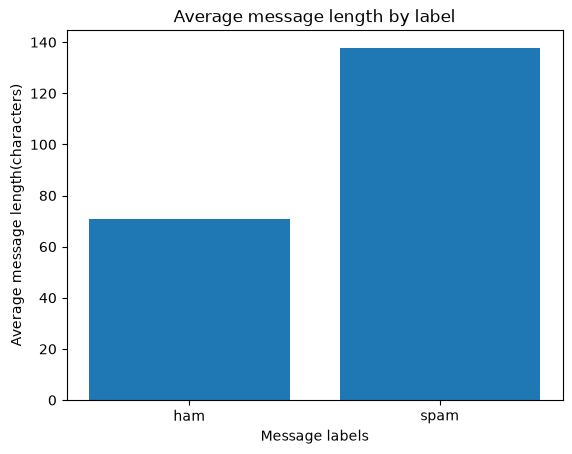

In [20]:
plt.bar(avg_length.index, avg_length)
plt.title('Average message length by label')
plt.xlabel('Message labels')
plt.ylabel('Average message length(characters)')
plt.show()

In [21]:
df_clean.shape

(5169, 3)

In [22]:
message_count = df_clean['label'].value_counts()

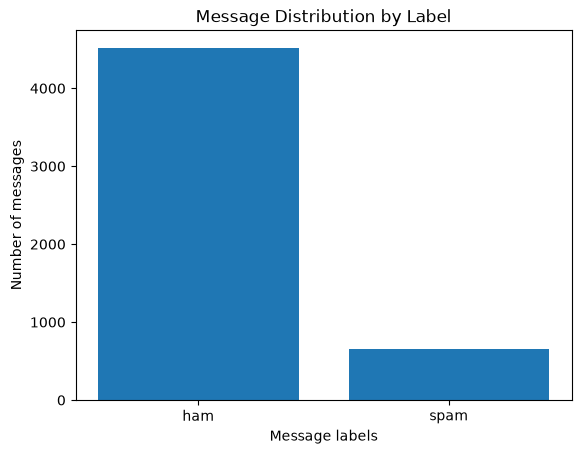

In [23]:
plt.bar(message_count.index, message_count)
plt.title('Message Distribution by Label')
plt.xlabel('Message labels')
plt.ylabel('Number of messages')
plt.show()

**EDA**

1. Loaded dataset from platform 'UCI SMS Spam Collection dataset'
2. Turned csv dataset into dataframe
3. Checked number of ham and spam messages, number of rows and columns of the dataframe 'df' and full information about dataframe,
4. Checked number of null values and duplicates rows 
5. Number of null values turned out to be 0 and duplicate rows to be 403
6. Find out how many same messages are labelled as both 'ham' and 'spam' using 'groupby' and 'nunique'
7. Droped duplicates and made another clean dataframe 'df_clean'
8. Find out ham message = 4516 and spam messages = 653
9. Created a new_column 'message_length' to find out the length of each message, sorted them in descending order and viewed top 5 messages
10. Created 'average_length' to find out the average lengthof all ham messages together and spam messages reseectively
11. Created a bar chart 'Average message length by label'
12. Created a bar chart 'Message distribution by label'

In [24]:
df_clean.to_csv(r'C:\Users\kk425\OneDrive\OSMD\data\processed\cleaned_messages.csv', index = False)

In [25]:
X = df_clean['message']
y = df_clean['label']

In [26]:
print(X.shape)
print(y.shape)

(5169,)
(5169,)


In [27]:
df_clean.to_csv(
    "../data/processed/cleaned_messages.csv", index = False
)